# Lab 5 · Building the training data: Bradley weather + Connecticut electricity load, 2023 to now

**OPIM 5512 · Module 4 · Dr. Dave**

Before you forecast anything, you need a clean history. This notebook builds the one we use all of Module 4 and the
final project: **every hour from Jan 1, 2023 to Oct 15, 2026**, with the weather at **Bradley Airport (BDL)** and the
electricity load of the **Connecticut zone** of the New England grid.

The golden rule: **one row per hour, no gaps, no duplicates.** Jan 1, 2023 to Oct 15, 2026 is 1,384 days (2024 is a
leap year) × 24 = 33,216 hours, **minus 1**: the period has four spring-forward days (23 hours) but only three fall-back
days (25 hours), because Nov 1, 2026 comes after Oct 15. So the final table must have exactly **33,215 rows**. We check
that at the end.

**The two sources**
| Data | Where it comes from | What it measures |
|---|---|---|
| Weather | Iowa State Mesonet archive of the official airport reports (METARs) at Bradley | Temperature, humidity, wind, clouds, rain, ... |
| Load | ISO New England web services, *real-time hourly demand*, Connecticut zone (location 4004) | Average megawatts (MW) used in Connecticut in that hour |

**The time trap: daylight saving.** Twice a year, local clock time breaks: in March one hour never happens, in November
one hour happens twice. If you join on local time you silently lose or double rows. So we store every time in **UTC**,
which never jumps, and add local time only at the very end for convenience.

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
YEARS = [2022, 2023, 2024, 2025, 2026]   # the last days of 2022 are padding for filling gaps at the start

## 1. The raw weather: what an airport report looks like
Bradley sends a **routine report at 51 minutes past every hour**, plus extra **special reports** whenever the weather
changes quickly (a storm rolls in, visibility drops). We downloaded every report from the Iowa State Mesonet, in UTC,
one file per year. (Want the live version? The download link is in the comments below. Please don't hammer it: the
Mesonet is a free service run by Iowa State University.)

In [2]:
# Download link (one year shown): https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py?station=BDL
#   &data=tmpf&data=dwpf&data=relh&data=drct&data=sknt&data=gust&data=p01i&data=alti&data=mslp&data=vsby
#   &data=skyc1&data=skyc2&data=skyc3&data=skyc4&data=wxcodes&data=feel&year1=2023&month1=1&day1=1&year2=2024&month2=1&day2=1
#   &tz=Etc%2FUTC&format=onlycomma&report_type=3&report_type=4      (3 = routine, 4 = special)
pieces = []
for year in YEARS:
    one_year = pd.read_csv(DATA + "raw/BDL_asos_" + str(year) + ".csv", na_values=["M"], keep_default_na=False)
    pieces.append(one_year)
raw = pd.concat(pieces, ignore_index=True)
raw["valid"] = pd.to_datetime(raw["valid"], utc=True)     # the report time, already in UTC
print(len(raw), "reports")
raw.head()

40876 reports


,station,valid,tmpf,dwpf,relh,drct,sknt,gust,p01i,alti,vsby,skyc1,skyc2,skyc3,skyc4,wxcodes,feel
0,BDL,2022-12-25 00:51:00+00:00,12.9,-4.0,46.02,240.0,17.0,20.0,0.00,29.76,10.0,CLR,NaN,NaN,NaN,NaN,-4.95
1,BDL,2022-12-25 01:51:00+00:00,12.0,-3.0,50.47,240.0,11.0,NaN,0.00,29.78,10.0,CLR,NaN,NaN,NaN,NaN,-2.81
2,BDL,2022-12-25 02:51:00+00:00,12.9,-4.0,46.02,240.0,13.0,23.0,0.00,29.78,10.0,CLR,NaN,NaN,NaN,NaN,-2.90
3,BDL,2022-12-25 03:51:00+00:00,12.9,-3.0,48.50,250.0,16.0,NaN,0.00,29.78,10.0,SCT,NaN,NaN,NaN,NaN,-4.48
4,BDL,2022-12-25 04:51:00+00:00,12.9,-3.0,48.50,230.0,16.0,21.0,0.00,29.78,10.0,BKN,NaN,NaN,NaN,NaN,-4.48


**What the columns mean** (US airport units): `tmpf` temperature (°F), `dwpf` dew point (°F), `relh` relative humidity
(%), `drct` wind direction (degrees), `sknt` wind speed (knots), `gust` gust (knots), `p01i` rain in the last hour
(inches), `alti` pressure (inches of mercury), `vsby` visibility (miles), `skyc1` to `skyc4` up to four cloud layers (CLR,
FEW, SCT, BKN, OVC), `wxcodes` weather codes (RA = rain, SN = snow, BR = mist, FG = fog), `feel` "feels like" (°F).

### Look at the mess before you clean it

In [3]:
minutes = raw["valid"].dt.minute
print("Reports at :51 (routine):", (minutes == 51).sum())
print("Other minutes (specials):", (minutes != 51).sum())
print()
print("Missing gust:", raw["gust"].isna().mean().round(3) * 100, "% of reports (no gust was reported)")
print("Trace rain 'T':", (raw["p01i"] == "T").sum(), "reports (too little to measure)")
print("Lowest-layer sky codes:", raw["skyc1"].value_counts().to_dict())
print("Reports with a 2nd cloud layer:", raw["skyc2"].notna().sum())

Reports at :51 (routine): 33458
Other minutes (specials): 7418

Missing gust: 87.7 % of reports (no gust was reported)
Trace rain 'T': 3662 reports (too little to measure)
Lowest-layer sky codes: {'FEW': 17753, 'BKN': 8901, 'SCT': 6290, 'OVC': 4524, 'CLR': 2895, 'VV ': 512}
Reports with a 2nd cloud layer: 25610


Four things to fix:
1. **Several reports in some hours** (specials), and a few hours with **none at all**.
2. **"T" for trace rain** is text in a number column.
3. **A missing gust** isn't missing data: it means no gust was reported.
4. **Sky cover is a code**, not a number, spread over up to **four layers** (a few low clouds can sit under a thick
   deck), and "VV" means the sky is hidden (fog), which counts as fully covered.

## 2. One report per hour, lined up with the load
ISO-NE labels each hour by when it **begins**: the 11:00 row is the load from 11:00 to 12:00. The 10:51 report
describes the weather right at the start of that hour, so we round each report to the **nearest hour** (10:51 → 11:00).
When an hour has more than one report, we keep the **routine** one; if there's no routine report, the one closest to the
hour.

In [4]:
raw["hour_utc"] = raw["valid"].dt.round("h")                      # 10:51 -> 11:00
raw["minutes_off"] = (raw["valid"] - raw["hour_utc"]).abs().dt.total_seconds() / 60
raw["is_routine"] = raw["valid"].dt.minute == 51

# Sort so that, within each hour, the routine report comes first, then the closest one; keep the first
raw = raw.sort_values(["hour_utc", "is_routine", "minutes_off"], ascending=[True, False, True])
hourly = raw.drop_duplicates("hour_utc", keep="first")
hourly = hourly.set_index("hour_utc")
print(len(raw), "reports ->", len(hourly), "hours with at least one report")

40876 reports -> 33471 hours with at least one report


## 3. A complete grid of hours, so the gaps show up
We build the full list of hours from midnight Jan 1, 2023 to 11 p.m. Oct 15, 2026, Connecticut time, written in UTC
(with 3 days of padding on each side), then line the reports up against it. Any
hour without a report becomes an empty row, which we flag as `weather_imputed = True`.

In [5]:
# Our days are Connecticut calendar days (that's how ISO New England reports them),
# so midnight Jan 1, 2023 in Connecticut = 05:00 UTC. We store the hours in UTC.
START = pd.Timestamp("2023-01-01 00:00", tz="America/New_York").tz_convert("UTC")
END = pd.Timestamp("2026-10-15 23:00", tz="America/New_York").tz_convert("UTC")      # the last full day of official load
grid = pd.date_range(START, END, freq="h")
print("First hour (UTC):", START, "| last hour (UTC):", END)
print("Hours from Jan 1, 2023 to Oct 15, 2026 (Connecticut time):", len(grid))

padded = pd.date_range(START - pd.Timedelta(hours=72), END + pd.Timedelta(hours=72), freq="h")
hourly = hourly.reindex(padded)
hourly["weather_imputed"] = hourly["station"].isna()
print("Hours with no report at all:", int(hourly.loc[grid, "weather_imputed"].sum()))

First hour (UTC): 2023-01-01 05:00:00+00:00 | last hour (UTC): 2026-10-16 03:00:00+00:00
Hours from Jan 1, 2023 to Oct 15, 2026 (Connecticut time): 33215
Hours with no report at all: 33


## 4. Tidy the values (and match the forecast's units)
Our hourly **forecast** scraper reads forecast.weather.gov, which gives wind in **mph** and sky cover in **percent**.
To make history and forecast directly comparable, we convert the airport reports to the same units now.

In [6]:
# Rain: "T" (trace) becomes a tiny amount, not zero, so "it drizzled" is still visible
hourly["precip_in"] = pd.to_numeric(hourly["p01i"].replace("T", "0.001"), errors="coerce")

# Wind: knots -> mph (1 knot = 1.15078 mph); no gust reported means gust = the wind speed
KNOTS_TO_MPH = 1.15078
hourly["wind_speed_mph"] = hourly["sknt"] * KNOTS_TO_MPH
hourly["wind_gust_mph"] = hourly["gust"].fillna(hourly["sknt"]) * KNOTS_TO_MPH

# Sky: cloud code -> percent of sky covered (the code's eighths of sky, at the middle of each range).
# A report can list up to 4 layers; the sky is as covered as its THICKEST layer (matches the forecast's "total" cover).
SKY_PERCENT = {"CLR": 0, "FEW": 19, "SCT": 44, "BKN": 75, "OVC": 100, "VV": 100}
layers = pd.DataFrame(index=hourly.index)
for layer in ["skyc1", "skyc2", "skyc3", "skyc4"]:
    layers[layer] = hourly[layer].str.strip().map(SKY_PERCENT)
hourly["cloud_cover_pct"] = layers.max(axis=1)

# Weather codes -> simple yes/no flags
codes = hourly["wxcodes"].fillna("")
hourly["is_rain"] = codes.str.contains("RA|DZ").astype(float)        # rain or drizzle
hourly["is_snow"] = codes.str.contains("SN|PL|GR|GS").astype(float)  # snow, sleet, hail
hourly["is_fog"] = codes.str.contains("FG|BR").astype(float)         # fog or mist

RENAME = {"tmpf": "temp_f", "dwpf": "dewpoint_f", "relh": "rel_humidity_pct", "feel": "feels_like_f",
          "drct": "wind_dir_deg", "alti": "pressure_inhg", "vsby": "visibility_mi"}
weather = hourly.rename(columns=RENAME)
COLUMNS = ["temp_f", "dewpoint_f", "rel_humidity_pct", "feels_like_f", "wind_speed_mph", "wind_gust_mph",
           "wind_dir_deg", "pressure_inhg", "visibility_mi", "cloud_cover_pct", "precip_in",
           "is_rain", "is_snow", "is_fog", "weather_imputed"]
weather = weather[COLUMNS]
weather.describe().T[["count", "min", "mean", "max"]].round(1)

,count,min,mean,max
temp_f,33326.0,-9.0,53.6,99.0
dewpoint_f,33326.0,-29.0,41.3,78.0
rel_humidity_pct,33326.0,9.6,66.3,100.0
feels_like_f,33325.0,-31.8,51.5,108.5
wind_speed_mph,33310.0,0.0,7.4,34.5
wind_gust_mph,33310.0,0.0,8.7,54.1
wind_dir_deg,32450.0,0.0,185.1,360.0
pressure_inhg,33326.0,28.9,30.0,31.0
visibility_mi,33325.0,0.1,9.2,10.0
cloud_cover_pct,33326.0,0.0,61.4,100.0


**Sanity check the ranges:** −9 °F to 99 °F, humidity about 10–100 %, wind under ~35 mph, visibility 0–10 miles. All
physically sensible for Connecticut, so there are no bad sensor values to remove. (If you ever see 150 °F or −80 °F,
that's a broken sensor: set it to missing and fill it like a gap.)

## 5. Fill the gaps (honestly)
For the few hours with no report: **numbers** are filled by drawing a straight line between the hours before and
after (time interpolation), but only across short gaps (6 hours at most). **Wind direction and the yes/no flags** take
the last known value. **Rain** with no report is set to 0. Every filled hour keeps `weather_imputed = True`, so a model
(or you) can tell real readings from filled ones.

In [7]:
NUMBERS = ["temp_f", "dewpoint_f", "rel_humidity_pct", "feels_like_f", "wind_speed_mph", "wind_gust_mph",
           "pressure_inhg", "visibility_mi", "cloud_cover_pct"]
FLAGS = ["is_rain", "is_snow", "is_fog"]

weather[NUMBERS] = weather[NUMBERS].interpolate(method="time", limit=6, limit_direction="both")
weather["wind_dir_deg"] = weather["wind_dir_deg"].ffill(limit=6)
weather[FLAGS] = weather[FLAGS].ffill(limit=6)
weather["precip_in"] = weather["precip_in"].fillna(0.0)

weather = weather.loc[grid]                                     # drop the padding

# Squeaky clean: sensible decimals, and yes/no flags as 0/1 integers
ROUNDING = {"temp_f": 1, "dewpoint_f": 1, "rel_humidity_pct": 1, "feels_like_f": 1, "wind_speed_mph": 1,
            "wind_gust_mph": 1, "wind_dir_deg": 0, "pressure_inhg": 2, "visibility_mi": 2, "cloud_cover_pct": 0,
            "precip_in": 3}
for column in ROUNDING:
    weather[column] = weather[column].round(ROUNDING[column])
for column in FLAGS:
    weather[column] = weather[column].astype(int)
weather["weather_imputed"] = weather["weather_imputed"].astype(int)
print("Rows:", len(weather))
print("Missing values left:", int(weather.isna().sum().sum()))
print("Filled (imputed) hours:", int(weather["weather_imputed"].sum()))

Rows: 33215


Missing values left: 0
Filled (imputed) hours: 33


## 6. The Connecticut load
We pulled ISO New England's **real-time hourly demand** for the Connecticut zone (location 4004), one day at a time,
through ISO Express web services (you'll get your own free account for the hourly scraper). Each row has the hour's
start time **with its UTC offset**: `-05:00` in winter (EST) and `-04:00` in summer (EDT). That offset is what makes the
daylight-saving hours unambiguous.

In [8]:
load_raw = pd.read_csv(DATA + "raw/ct_hourly_load_2023_2026_raw.csv")
print(len(load_raw), "rows")
load_raw.head()

33215 rows


,begin_date,location,loc_id,load_mw
0,2023-01-01T00:00:00.000-05:00,.Z.CONNECTICUT,4004,2402.708
1,2023-01-01T01:00:00.000-05:00,.Z.CONNECTICUT,4004,2296.444
2,2023-01-01T02:00:00.000-05:00,.Z.CONNECTICUT,4004,2206.413
3,2023-01-01T03:00:00.000-05:00,.Z.CONNECTICUT,4004,2165.396
4,2023-01-01T04:00:00.000-05:00,.Z.CONNECTICUT,4004,2153.655


In [9]:
# Parse each local time with its own offset, then convert to UTC
load = load_raw.copy()
load["hour_utc"] = pd.to_datetime(load["begin_date"], utc=True)

# Look at the two daylight-saving days of 2024
load["local_day"] = pd.to_datetime(load["begin_date"].str.slice(0, 10))
per_day = load.groupby("local_day").size()
print("Hours in a normal local day:", per_day.mode()[0])
print("Days that aren't 24 hours (daylight saving):")
print(per_day[per_day != 24])

Hours in a normal local day: 24
Days that aren't 24 hours (daylight saving):
local_day
2023-03-12    23
2023-11-05    25
2024-03-10    23
2024-11-03    25
2025-03-09    23
2025-11-02    25
2026-03-08    23
dtype: int64


March days have **23** hours (2 a.m. never happens) and November days have **25** (1 a.m. happens twice). In UTC
every one of those hours is distinct, so nothing collides.

In [10]:
load = load.drop_duplicates("hour_utc").set_index("hour_utc").sort_index()
load = load.reindex(grid)
print("Load hours:", len(load), "| missing:", int(load["load_mw"].isna().sum()))

Load hours: 33215 | missing: 0


## 7. Join, check, save

In [11]:
df = weather.join(load[["load_mw"]], how="left")
df.index.name = "hour_utc"

# Local time, for humans (and for features like "hour of the day" later)
df["hour_local"] = df.index.tz_convert("America/New_York").strftime("%Y-%m-%d %H:%M %Z")

# The golden rule checks
assert len(df) == 33215, "rows must equal hours"
assert df.index.is_unique, "no duplicate hours"
assert df.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all(), "no gaps"
assert df["load_mw"].notna().all(), "every hour has load"
assert df[NUMBERS].notna().all().all(), "every hour has weather"
print("All checks passed:", len(df), "rows, one per hour, no gaps, no duplicates, nothing missing.")
df.head()

All checks passed: 33215 rows, one per hour, no gaps, no duplicates, nothing missing.


,temp_f,dewpoint_f,rel_humidity_pct,feels_like_f,wind_speed_mph,wind_gust_mph,wind_dir_deg,pressure_inhg,visibility_mi,cloud_cover_pct,precip_in,is_rain,is_snow,is_fog,weather_imputed,load_mw,hour_local
hour_utc,,,,,,,,,,,,,,,,,
2023-01-01 05:00:00+00:00,50.0,48.0,92.8,50.0,9.2,9.2,180.0,29.70,0.25,100.0,0.04,1,0,1,0,2402.708,2023-01-01 00:00 EST
2023-01-01 06:00:00+00:00,50.0,49.0,96.0,50.0,8.1,8.1,170.0,29.69,3.00,100.0,0.02,1,0,1,0,2296.444,2023-01-01 01:00 EST
2023-01-01 07:00:00+00:00,50.0,49.0,96.0,50.0,8.1,8.1,220.0,29.68,0.75,100.0,0.01,0,0,1,0,2206.413,2023-01-01 02:00 EST
2023-01-01 08:00:00+00:00,48.0,48.0,100.0,48.0,0.0,0.0,0.0,29.68,3.00,75.0,0.00,0,0,1,0,2165.396,2023-01-01 03:00 EST
2023-01-01 09:00:00+00:00,48.0,46.0,92.7,47.0,3.5,3.5,210.0,29.69,1.00,44.0,0.00,0,0,1,0,2153.655,2023-01-01 04:00 EST


In [12]:
df.to_csv("bdl_ct_load_hourly_2023_2026.csv")
print("Saved bdl_ct_load_hourly_2023_2026.csv")

Saved bdl_ct_load_hourly_2023_2026.csv


## 8. First look: why weather predicts electricity
Connecticut uses the most electricity when it's **hot** (air conditioning) and a lot when it's **cold** (heating and
lighting), and the least on mild spring and fall days. That's a **U-shape**, and it's why temperature is the star
feature for load forecasting.

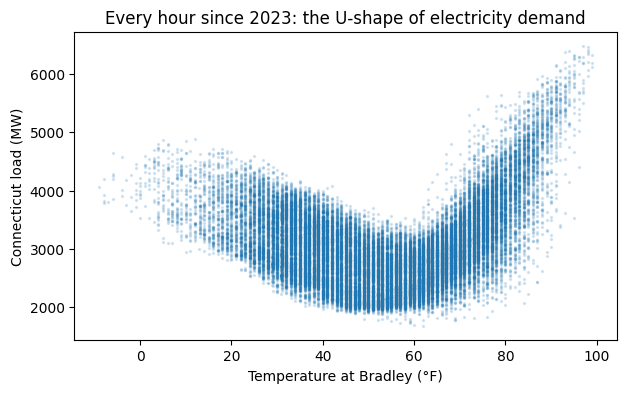

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["temp_f"], df["load_mw"], s=2, alpha=0.15)
ax.set_xlabel("Temperature at Bradley (°F)")
ax.set_ylabel("Connecticut load (MW)")
ax.set_title("Every hour since 2023: the U-shape of electricity demand")
plt.show()

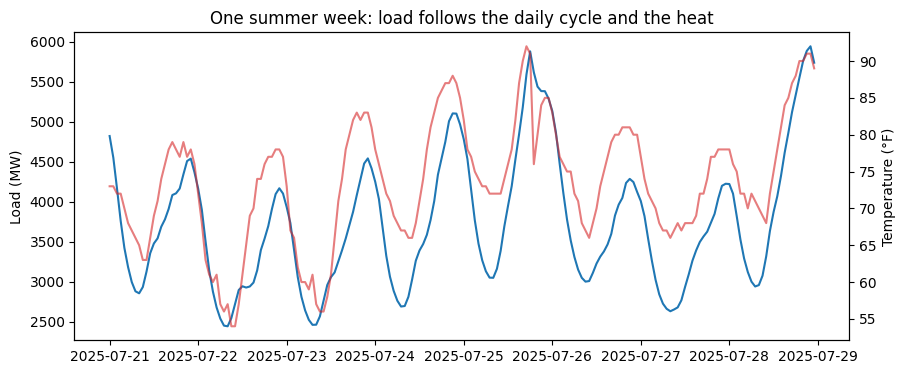

In [14]:
week = df.loc["2025-07-21":"2025-07-28"]
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(week.index, week["load_mw"], label="Connecticut load (MW)")
ax1.set_ylabel("Load (MW)")
ax2 = ax1.twinx()
ax2.plot(week.index, week["temp_f"], color="tab:red", alpha=0.6, label="Temperature (°F)")
ax2.set_ylabel("Temperature (°F)")
ax1.set_title("One summer week: load follows the daily cycle and the heat")
plt.show()

## What you have now
A table you can trust: **33,215 hours**, weather and load side by side, in UTC, nothing missing, every filled value
flagged. Next in Lab 5: turn the timestamp into features (hour of the day, day of the week, holidays), add **lags**
(the load 24 hours ago), and fit your first real forecasting model.

**Data credits:** weather from the Iowa State Mesonet (mesonet.agron.iastate.edu) archive of NWS/FAA airport reports;
load from ISO New England (iso-ne.com, ISO Express web services, real-time hourly demand, Connecticut load zone).